# Домашнее задание № 3 — анализ IT-вакансий и классификация рекламных объявлений

**Студент:** Митяева Дарья Викторовна, 3823Б1ФИ2  
**Дисциплина:** Машинное обучение  
**Датасет:** [ScoutieAutoML/it_vacancies_vectorisation](https://huggingface.co/datasets/ScoutieAutoML/it_vacancies_vectorisation)

## 0. Постановка задачи

Объект исследования — публикация об IT-вакансии в Telegram-канале. Цель работы — предсказать класс публикации (`SPAM` или `NOT SPAM`) на основе текста объявления и дополнительных характеристик. В данном наборе метка `SPAM` относится к рекламным публикациям и не означает, что вакансия является мошеннической.

Задача относится к **бинарной классификации**. Исходный датасет содержит **51 078 объектов** и **30 полей**, включая целевую переменную `spam`. Поле `vector` содержит готовые векторные представления текста, а не отдельное скалярное значение.

Для вычислений используется подвыборка из 14 000 записей с потоковым перемешиванием (`seed = 42`, буфер 3 000). После удаления повторов в анализе остаётся 12 958 объектов. Выборка не является строго равномерной случайной выборкой всего набора, поэтому полученные метрики относятся именно к ней. Метки классов сформированы автоматически, что может влиять на их достоверность.

## Подготовка рабочей среды

Для загрузки данных и обучения моделей использованы библиотеки `datasets`, `pandas`, `numpy`, `matplotlib` и `scikit-learn`. Для воспроизводимости эксперимента фиксируется случайное зерно (`random_state = 42`).

In [1]:
# Установка библиотек для обработки данных и машинного обучения.
%pip -q install "datasets>=3.0,<5" "scikit-learn>=1.3" pandas matplotlib


In [2]:
from itertools import islice
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Значение random_state фиксируется для воспроизводимости разбиения.
RANDOM_STATE = 42
DATASET_ID = "ScoutieAutoML/it_vacancies_vectorisation"
MAX_ROWS = 14_000        # Размер подвыборки для запуска в Colab
K_VALUES = [3, 7, 15, 31]  # Проверяемые значения числа соседей k
np.random.seed(RANDOM_STATE)
print("Библиотеки загружены")


Библиотеки загружены


## 1. Чтение данных

Столбцы `vector` (~9,5 тысяч символов на запись) и `ners` (JSON-разметка именованных сущностей) пропускаем: они занимают много памяти и в первой модели не используются. Потоковое чтение не требует скачивать 972 МБ CSV как один локальный файл, но чтение источника все равно может занять время.

In [3]:
# Потоковая загрузка позволяет не держать исходный набор целиком в памяти.
stream = load_dataset(DATASET_ID, split="train", streaming=True)
stream = stream.shuffle(seed=RANDOM_STATE, buffer_size=3_000)
# Для эксперимента отбираются 14 000 записей; поля с готовыми векторами не используются.
rows = []
for record in islice(stream, MAX_ROWS):
    rows.append({key: value for key, value in record.items()
                 if key not in {"vector", "ners"}})

df_raw = pd.DataFrame(rows)
print("Загружено строк:", len(df_raw))
print("Столбцов в рабочей таблице:", df_raw.shape[1])
display(df_raw.head(3).T)
assert {'text', 'spam'}.issubset(df_raw.columns), "В исходных данных изменились названия столбцов"


README.md:   0%|          | 0.00/4.38k [00:00<?, ?B/s]

Загружено строк: 14000
Столбцов в рабочей таблице: 28


,0,1,2
taskId,107,107,107
title,None,None,None
text,#вакансия #удаленка #работа #systemanalyst #си...,"Привет, на связи редакция. Мы агрегируем вакан...",#вакансия #Москва #Fulltime #Senior #ML #Highl...
url,https://t.me/datascienceml_jobs/1223?embed=1&m...,https://t.me/opento_data/94?embed=1&mode=tme,https://t.me/datasciencejobs/2294?embed=1&mode...
sourceLink,https://t.me/,https://t.me/,https://t.me/
subSourceLink,https://t.me/s/datascienceml_jobs,https://t.me/s/opento_data,https://t.me/s/datasciencejobs
views,3200,1400,5100
likes,0,0,0
createTime,1732622456,1706103266,1725346991
crawlTime,1734688970,1734689032,1734689024


## 2. Контроль качества, удаление повторов и разделение

Удаляем только полностью пустые тексты и полные дубликаты текста, чтобы одинаковое объявление не попало в обучение и тест одновременно. До обучения выделяем **тест (20%)**, затем внутри оставшихся данных **валидацию (25% от остатка = 20% всех строк)**. Итоговое разделение: 60% обучение, 20% валидация, 20% тест. Сохраняем пропорции классов.

In [4]:
# Сначала оцениваются пропуски и количество повторов.
print("Пропуски по столбцам, %:")
display((df_raw.isna().mean().mul(100).round(2).sort_values(ascending=False)).to_frame('missing_pct'))
print("Исходных дубликатов по тексту:", df_raw['text'].fillna('').duplicated().sum())

# Удаление повторов по тексту исключает попадание одной публикации в разные выборки.
df = df_raw.copy()
df['text'] = df['text'].fillna('').astype(str).str.strip()
df = df[df['text'].str.len() > 0].drop_duplicates(subset='text').copy()
df['spam'] = df['spam'].astype(str).str.upper().str.strip().str.replace('_', ' ', regex=False)
df = df[df['spam'].isin(['SPAM', 'NOT SPAM'])].copy()
assert df['spam'].nunique() == 2, "После очистки не осталось двух классов. Изучите разметку."
print("После очистки:", df.shape)
print("Распределение классов:")
display(pd.DataFrame({'count':df['spam'].value_counts(),
                      'percent':df['spam'].value_counts(normalize=True).mul(100).round(2)}))

# Целевая переменная: 0 — NOT SPAM, 1 — SPAM.
y = df['spam'].map({'NOT SPAM':0, 'SPAM':1}).astype(int)
X = df.drop(columns=['spam']).copy()
# Данные делятся на обучение (60%), валидацию (20%) и тест (20%) с сохранением долей классов.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,y_train_val, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_train_val)
print('Размеры:', len(X_train),'train;',len(X_val),'validation;',len(X_test),'test')


Пропуски по столбцам, %:


,missing_pct
title,100.0
taskId,0.0
text,0.0
url,0.0
sourceLink,0.0
subSourceLink,0.0
views,0.0
likes,0.0
createTime,0.0
crawlTime,0.0


Исходных дубликатов по тексту: 1042
После очистки: (12958, 28)
Распределение классов:


,count,percent
spam,,
NOT SPAM,8184,63.16
SPAM,4774,36.84


Размеры: 7774 train; 2592 validation; 2592 test


## 3. Визуализация, описательные статистики, корреляция

Проверяем, как распределены просмотры и длины текстов. Просмотры могут иметь длинный правый хвост, поэтому в диаграммах используем `log1p`. Корреляция Пирсона показывает линейную связь **числовых** столбцов; она сама по себе не устанавливает причинность. `text` — **свободный текст**, а `language` и `subSourceLink` — **категории**.

### 3.1. Описательные статистики

Среднее характеризует типичный уровень числового признака, стандартное отклонение — разброс значений; медиана и квартильные границы помогают заметить асимметрию распределений.

In [5]:
# Описательные статистики рассчитываются только для числовых полей.
BASE_NUM = ['views','length','swearWordsCount','capslockWordsCount','ru','eng','other',
            'adj','verb','pron','num','noun','adv','punc']
BASE_NUM = [c for c in BASE_NUM if c in df.columns]
eda_num = df[BASE_NUM].apply(pd.to_numeric, errors='coerce')
print('Описательные статистики:')
display(eda_num.describe().T.round(2))

Описательные статистики:


,count,mean,std,min,25%,50%,75%,max
views,12958.0,1748.67,3313.04,1.0,677.00,1400.00,1800.00,201600.00
length,12958.0,176.26,114.40,1.0,87.00,142.00,244.00,609.00
swearWordsCount,12958.0,0.02,0.16,0.0,0.00,0.00,0.00,2.00
capslockWordsCount,12958.0,8.78,7.39,0.0,4.00,7.00,12.00,85.00
ru,12958.0,0.89,0.09,0.0,0.87,0.91,0.94,1.00
eng,12958.0,0.11,0.09,0.0,0.06,0.09,0.13,1.00
other,12958.0,0.00,0.00,0.0,0.00,0.00,0.00,0.07
adj,12958.0,17.45,14.42,0.0,6.00,13.00,25.00,126.00
verb,12958.0,12.19,11.59,0.0,4.00,8.00,17.00,88.00
pron,12958.0,4.00,5.23,0.0,0.00,2.00,6.00,49.00


### 3.2. Распределения признаков и целевой переменной

На гистограмме просмотров используется преобразование `log(1 + views)`: оно делает длинный правый хвост более читаемым, сохраняя порядок значений.

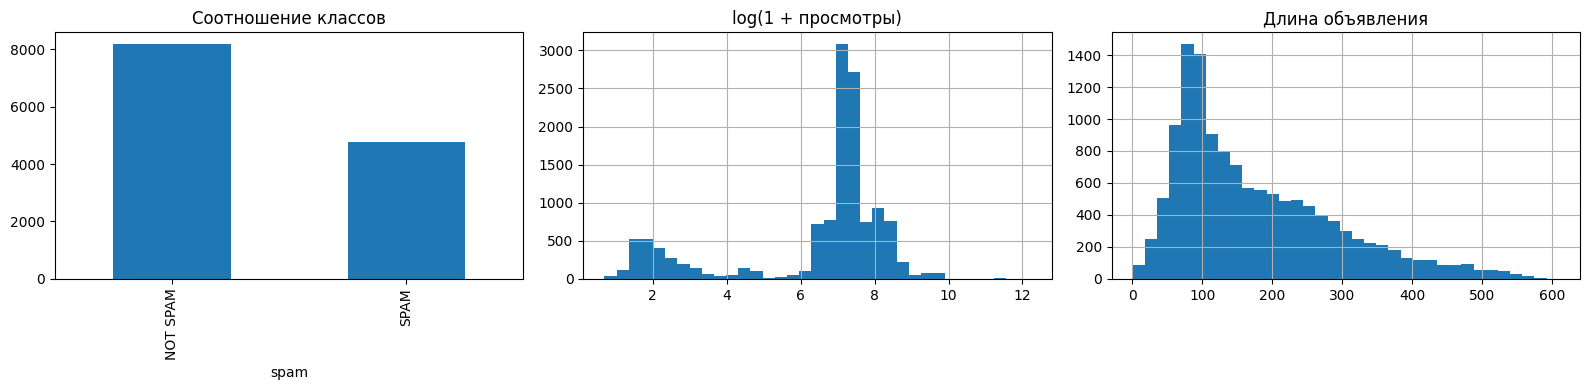

In [6]:
fig, axes = plt.subplots(1,3,figsize=(16,4))
df['spam'].value_counts().plot(kind='bar', ax=axes[0], title='Соотношение классов')
if 'views' in eda_num:
    # Логарифм сглаживает влияние очень больших значений просмотров.
    np.log1p(eda_num['views'].clip(lower=0)).hist(bins=35, ax=axes[1])
    axes[1].set_title('log(1 + просмотры)')
if 'length' in eda_num:
    eda_num['length'].hist(bins=35,ax=axes[2]); axes[2].set_title('Длина объявления')
plt.tight_layout();plt.show()

### 3.3. Связь просмотров и длины объявления

Диаграмма рассеяния показывает отдельные публикации. По оси X — длина текста, по оси Y — логарифм просмотров; цвет задаёт класс. Сам по себе график не доказывает, что один признак является причиной другого.

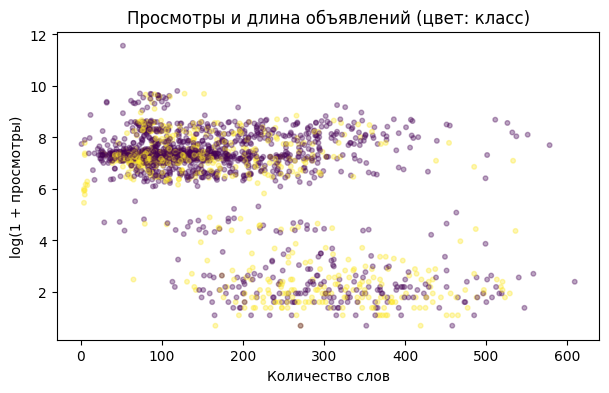

In [7]:
if {'views','length'}.issubset(eda_num.columns):
    tmp = df.sample(n=min(2_000,len(df)),random_state=RANDOM_STATE)
    plt.figure(figsize=(7,4))
    plt.scatter(pd.to_numeric(tmp['length'],errors='coerce'),
                np.log1p(pd.to_numeric(tmp['views'],errors='coerce').clip(lower=0)),
                c=tmp['spam'].map({'NOT SPAM':0,'SPAM':1}), alpha=.35, s=11)
    plt.title('Просмотры и длина объявлений (цвет: класс)')
    plt.xlabel('Количество слов');plt.ylabel('log(1 + просмотры)')
    plt.show()

### 3.4. Корреляционная матрица

Коэффициент Пирсона находится между −1 и 1. Значения около 1 или −1 указывают на сильную линейную связь, а значения около 0 — на слабую линейную связь.

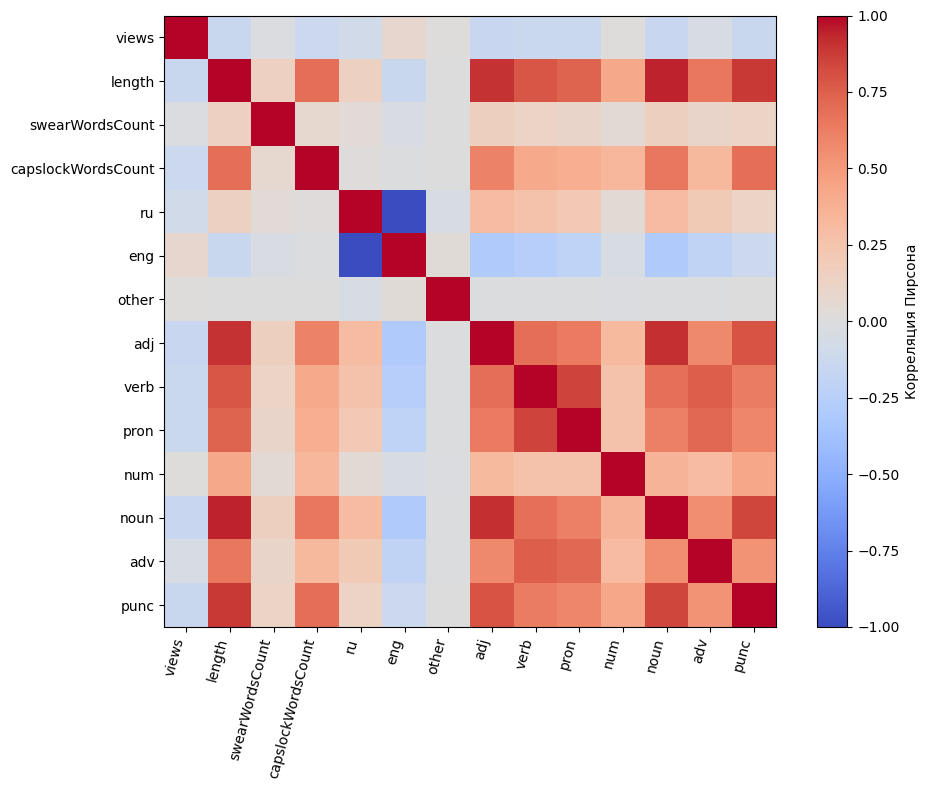

Наиболее сильные по модулю корреляции:
ru      eng    -0.999935
length  noun    0.943835
adj     noun    0.909679
length  adj     0.902412
        punc    0.886944
verb    pron    0.845198
noun    punc    0.841507
adj     punc    0.793466
dtype: float64


In [8]:
# Корреляция Пирсона оценивает линейную связь, но не доказывает причинность.
corr = eda_num.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(corr, vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr.columns)),labels=corr.columns,rotation=75,ha='right')
ax.set_yticks(range(len(corr.index)),labels=corr.index)
fig.colorbar(im,ax=ax,label='Корреляция Пирсона');plt.tight_layout();plt.show()
if len(corr)>1:
    m = corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(key=np.abs,ascending=False)
    print('Наиболее сильные по модулю корреляции:');print(m.head(8))

**Вывод по исследованию распределений и корреляций.** У признака `views` среднее составляет 1 748,67, медиана — 1 400, а максимум достигает 201 600. Следовательно, распределение просмотров асимметрично: отдельные публикации набирают намного больше просмотров, чем большинство остальных.

Между `ru` и `eng` получена почти идеальная отрицательная корреляция (**r ≈ −0,9999**), а между `length` и `noun` — высокая положительная (**r ≈ 0,9438**). Второе закономерно: в длинных текстах чаще встречается больше существительных. Такие связи показывают, что часть числовых характеристик дублирует информацию друг друга. Это стоит учитывать при интерпретации модели; корреляция не доказывает причинно-следственную связь.

## 4. Подготовка признаков и анализ выбросов

Для обучения не используем идентификаторы и ссылки: они в первую очередь обозначают конкретную публикацию, а не её содержание. Из `createTime` получаем час и день недели, `views` преобразуем через `log1p`. Преобразования одинаково применяются к обучающей, валидационной и тестовой частям.

Выбросы определяем методом межквартильного размаха (**IQR = Q3 − Q1**). Значение считаем выбросом, если оно находится ниже `Q1 − 1,5 × IQR` или выше `Q3 + 1,5 × IQR`. Границы определяем только на **train**, чтобы не использовать распределения валидационных и тестовых данных при настройке обработки.

In [9]:
NUMERIC_FEATURES = BASE_NUM + ['post_hour','post_weekday']
CATEGORICAL_FEATURES = [c for c in ['language','sentiment','subSourceLink'] if c in X.columns]

# Для каждой части данных используется одинаковый набор признаков и преобразований.
def prepare_features(frame):
    out = frame.copy()
    timestamp = pd.to_datetime(pd.to_numeric(out.get('createTime'),errors='coerce'),unit='s',utc=True,errors='coerce')
    out['post_hour'] = timestamp.dt.hour
    out['post_weekday'] = timestamp.dt.dayofweek
    for name in BASE_NUM:
        out[name] = pd.to_numeric(out[name],errors='coerce')
    if 'views' in out:
        out['views'] = np.log1p(out['views'].clip(lower=0))
    out['text'] = out['text'].fillna('').astype(str)
    for name in CATEGORICAL_FEATURES:
        out[name] = out[name].astype('string').replace({'<NA>':pd.NA}).astype(object)
        out.loc[out[name].isna(),name] = np.nan
    return out[['text']+NUMERIC_FEATURES+CATEGORICAL_FEATURES].copy()

A_train = prepare_features(X_train)
A_val = prepare_features(X_val)
A_test = prepare_features(X_test)

### 4.1. Boxplot до ограничения выбросов

График с «ящиком и усами» показывает медиану, квартили и значения за пределами усов. Смотрим логарифм просмотров и длину текста **до** ограничения выбросов.

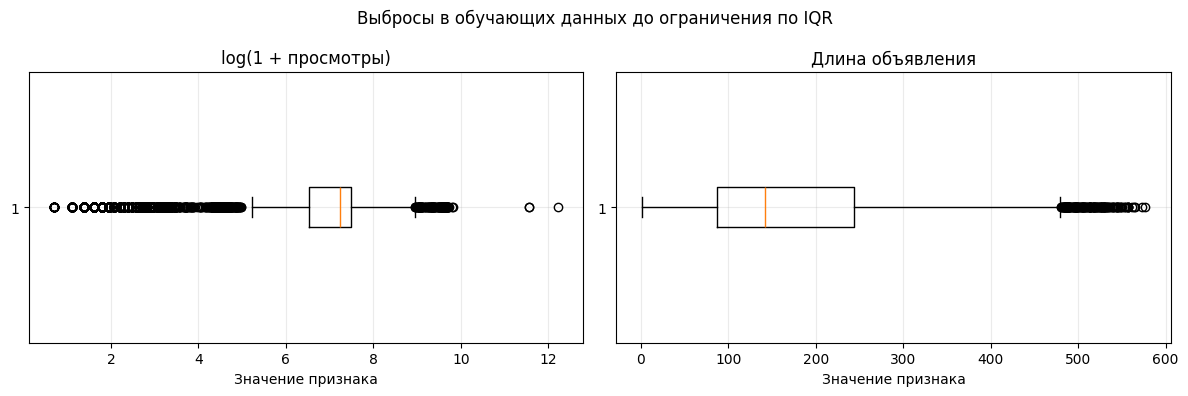

In [10]:
# Строим boxplot по обучающей выборке до обработки выбросов.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, label in zip(
    axes,
    ['views', 'length'],
    ['log(1 + просмотры)', 'Длина объявления']
):
    values = A_train[name].dropna().to_numpy()
    ax.boxplot(values, vert=False)
    ax.set_title(label)
    ax.set_xlabel('Значение признака')
    ax.grid(alpha=0.25)
plt.suptitle('Выбросы в обучающих данных до ограничения по IQR')
plt.tight_layout()
plt.show()

### 4.2. Расчёт границ и ограничение выбросов

Редкие публикации могут быть важны для классификации, поэтому строки не удаляем. Числовые значения за пределами границ заменяем ближайшей границей, рассчитанной на обучении.

In [11]:
# Границы выбросов по IQR рассчитываются только на обучающей части данных.
q1 = A_train[NUMERIC_FEATURES].quantile(0.25)
q3 = A_train[NUMERIC_FEATURES].quantile(0.75)
iqr = q3-q1
lower = q1-1.5*iqr
upper = q3+1.5*iqr
valid_iqr = iqr > 0
raw_outliers = ((A_train[NUMERIC_FEATURES].lt(lower)&valid_iqr) |
                (A_train[NUMERIC_FEATURES].gt(upper)&valid_iqr))
print('Процент объектов в train с >= 1 числовым выбросом:',
      round(100*raw_outliers.any(axis=1).mean(),2))
# Выбросы ограничиваются по границам, найденным на обучении; записи не удаляются.
for block in [A_train,A_val,A_test]:
    if valid_iqr.any():
        use_cols = list(valid_iqr[valid_iqr].index)
        block[use_cols] = block[use_cols].clip(lower=lower[use_cols],upper=upper[use_cols],axis=1)

Процент объектов в train с >= 1 числовым выбросом: 32.18


## 5. Обработка пропущенных значений

В исходной подвыборке столбец `title` полностью пустой (100% пропусков), поэтому он исключён из набора признаков модели. Если среди используемых числовых полей встретятся пропуски, `SimpleImputer` заменит их **медианой обучающей выборки**; медиана менее чувствительна к выбросам, чем среднее. Для категорий используем наиболее частое значение.

Все значения для заполнения будут определены в составе `Pipeline` во время `fit` на обучающих данных, а затем тем же преобразованием обработаются проверочные данные.

In [12]:
# Числовые пропуски заполняются медианой, значения нормализуются для kNN.
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median',add_indicator=False)),
    ('scaler',MinMaxScaler())
])

## 6. Кодирование категориальных признаков

Используем `language`, `sentiment` и `subSourceLink`. `OneHotEncoder` создаёт отдельные двоичные признаки для категорий; `handle_unknown="ignore"` позволяет обрабатывать категории, не встречавшиеся при обучении. Эти поля отличаются от свободного текста `text`: их значения выбираются из ограниченного набора категорий.

In [13]:
# Категориальные признаки кодируются One-Hot; незнакомые категории не вызывают ошибку.
cat_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore'))
])

## 7. Нормализация числовых признаков и представление текста

`MinMaxScaler` в числовом конвейере переводит значения в сопоставимый масштаб по обучающим данным. Это особенно важно для kNN, где объекты сравниваются по расстоянию.

`TfidfVectorizer` превращает свободный текст объявлений в числовые характеристики слов и пар слов. Ограничение `max_features=300` сдерживает размерность и вычислительные затраты. `ColumnTransformer` объединяет текстовые, числовые и категориальные преобразования в единый процесс.

In [14]:
# TF-IDF превращает слова и пары слов в числовые признаки; Pipeline обучает преобразования на train.
def make_preprocessor():
    return ColumnTransformer([
        ('text',TfidfVectorizer(max_features=300,min_df=3,ngram_range=(1,2)), 'text'),
        ('numbers',num_pipeline,NUMERIC_FEATURES),
        ('categories',cat_pipeline,CATEGORICAL_FEATURES)
    ])
print('Числовых признаков модели:',len(NUMERIC_FEATURES))
print('Категориальных исходных признаков:',len(CATEGORICAL_FEATURES))
print('Свободных текстовых полей:',1)

Числовых признаков модели: 16
Категориальных исходных признаков: 3
Свободных текстовых полей: 1


## 8. Обучение kNN и выбор количества соседей

Алгоритм k ближайших соседей определяет класс по похожим примерам. Перебираем `k = 3, 7, 15, 31`. Лучшее значение выбираем **по macro-F1 на валидации**, а не по тестовым данным. Macro-F1 — среднее F1 по каждому из двух классов, поэтому метрика учитывает и качество распознавания `SPAM`, и качество распознавания `NOT SPAM`.

{'model': 'kNN(k=3)', 'k': 3, 'accuracy': 0.7600308641975309, 'balanced_accuracy': np.float64(0.7389100864498013), 'macro_f1': 0.7404461387872856}
{'model': 'kNN(k=7)', 'k': 7, 'accuracy': 0.7692901234567902, 'balanced_accuracy': np.float64(0.7427505940825223), 'macro_f1': 0.7470864661654135}
{'model': 'kNN(k=15)', 'k': 15, 'accuracy': 0.7673611111111112, 'balanced_accuracy': np.float64(0.7342434602948185), 'macro_f1': 0.7409947908165252}
{'model': 'kNN(k=31)', 'k': 31, 'accuracy': 0.7623456790123457, 'balanced_accuracy': np.float64(0.7248196963542682), 'macro_f1': 0.7326388888888888}


,model,k,accuracy,balanced_accuracy,macro_f1
0,kNN(k=3),3,0.7600,0.7389,0.7404
1,kNN(k=7),7,0.7693,0.7428,0.7471
2,kNN(k=15),15,0.7674,0.7342,0.7410
3,kNN(k=31),31,0.7623,0.7248,0.7326


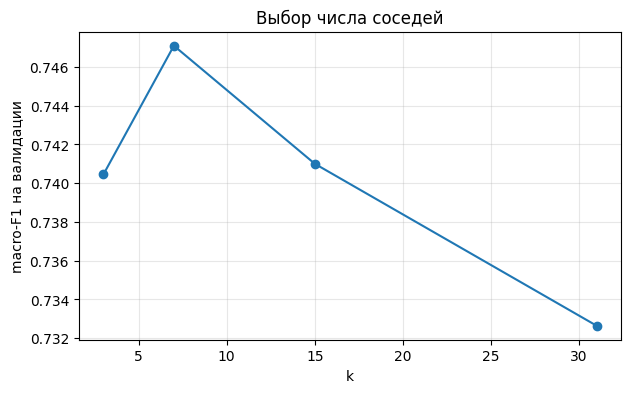

Оптимальное k (по валидации): 7


In [15]:
# k выбирается по macro-F1 на валидации; тест для подбора не используется.
validation_results=[]
for k in K_VALUES:
    # Pipeline объединяет подготовку признаков и модель kNN.
    pipeline=Pipeline([
        ('preprocess',make_preprocessor()),
        ('model',KNeighborsClassifier(n_neighbors=k,weights='distance',n_jobs=-1))
    ])
    pipeline.fit(A_train,y_train)
    pred=pipeline.predict(A_val)
    result={'model':f'kNN(k={k})','k':k,
            'accuracy':accuracy_score(y_val,pred),
            'balanced_accuracy':balanced_accuracy_score(y_val,pred),
            'macro_f1':f1_score(y_val,pred,average='macro',zero_division=0)}
    validation_results.append(result)
    print(result)

validation_table=pd.DataFrame(validation_results).sort_values('k')
display(validation_table.round(4))
plt.figure(figsize=(7,4))
plt.plot(validation_table['k'],validation_table['macro_f1'],marker='o')
plt.xlabel('k');plt.ylabel('macro-F1 на валидации');plt.title('Выбор числа соседей')
plt.grid(alpha=.3);plt.show()
# Выбирается k с наибольшим macro-F1, при равенстве — меньшее значение.
best_k=int(validation_table.sort_values(['macro_f1','k'],ascending=[False,True]).iloc[0]['k'])
print('Оптимальное k (по валидации):',best_k)


## 9. Сравнение моделей и оценка ошибок

После выбора `k` обучаем финальные модели на объединённых обучающей и валидационной выборках. Сравниваем kNN с логистической регрессией и `DummyClassifier`, который всегда предсказывает наиболее частый класс. Тестовая выборка используется для окончательной оценки.

Матрица рассогласования показывает количество правильных и неправильных предсказаний каждого класса. Печатаем её для обучения и теста, чтобы оценить разрыв в качестве.


== kNN(k=7) ==
Матрица рассогласования (TRAIN):
 [[6547    0]
 [   0 3819]]
Матрица рассогласования (TEST):
 [[1378  259]
 [ 361  594]]
              precision    recall  f1-score   support

    NOT SPAM       0.79      0.84      0.82      1637
        SPAM       0.70      0.62      0.66       955

    accuracy                           0.76      2592
   macro avg       0.74      0.73      0.74      2592
weighted avg       0.76      0.76      0.76      2592



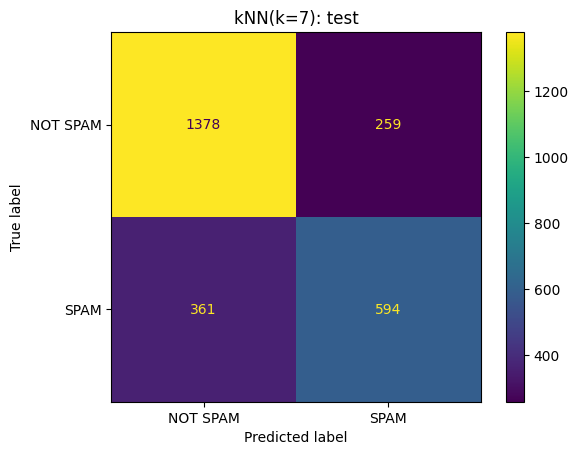


== LogisticRegression ==
Матрица рассогласования (TRAIN):
 [[5379 1168]
 [ 732 3087]]
Матрица рассогласования (TEST):
 [[1326  311]
 [ 207  748]]
              precision    recall  f1-score   support

    NOT SPAM       0.86      0.81      0.84      1637
        SPAM       0.71      0.78      0.74       955

    accuracy                           0.80      2592
   macro avg       0.79      0.80      0.79      2592
weighted avg       0.81      0.80      0.80      2592



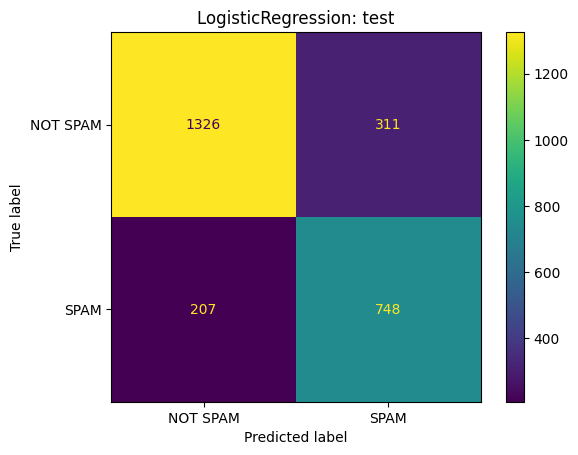


== Dummy majority ==
Матрица рассогласования (TRAIN):
 [[6547    0]
 [3819    0]]
Матрица рассогласования (TEST):
 [[1637    0]
 [ 955    0]]
              precision    recall  f1-score   support

    NOT SPAM       0.63      1.00      0.77      1637
        SPAM       0.00      0.00      0.00       955

    accuracy                           0.63      2592
   macro avg       0.32      0.50      0.39      2592
weighted avg       0.40      0.63      0.49      2592



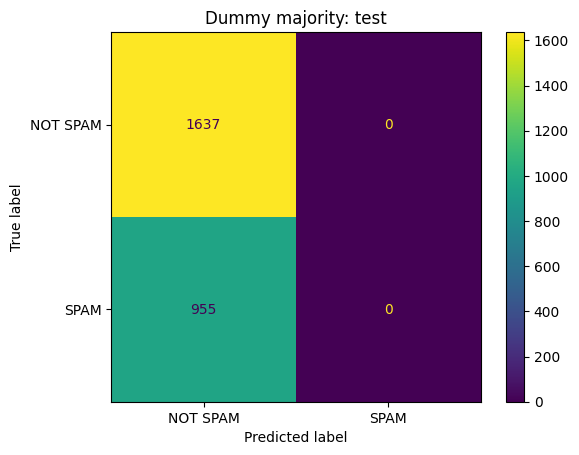

,model,train_accuracy,test_accuracy,test_balanced_accuracy,train_macro_f1,test_macro_f1
1,LogisticRegression,0.8167,0.8002,0.7966,0.8073,0.7897
0,kNN(k=7),1.0000,0.7608,0.7319,1.0000,0.7367
2,Dummy majority,0.6316,0.6316,0.5000,0.3871,0.3871


In [16]:
# После выбора k модель обучается на объединённых train и validation.
A_train_final=pd.concat([A_train,A_val],axis=0)
y_train_final=pd.concat([y_train,y_val],axis=0)
# Логистическая регрессия и DummyClassifier нужны для сравнения с kNN.
models={
    f'kNN(k={best_k})':Pipeline([
        ('preprocess',make_preprocessor()),
        ('model',KNeighborsClassifier(n_neighbors=best_k,weights='distance',n_jobs=-1))]),
    'LogisticRegression':Pipeline([
        ('preprocess',make_preprocessor()),
        ('model',LogisticRegression(max_iter=1500,class_weight='balanced'))]),
    'Dummy majority':DummyClassifier(strategy='most_frequent')
}

scores=[]
for name, model in models.items():
    model.fit(A_train_final,y_train_final)
    # Разница метрик train и test позволяет оценить обобщающую способность.
    p_train=model.predict(A_train_final)
    p_test=model.predict(A_test)
    scores.append({'model':name,
                   'train_accuracy':accuracy_score(y_train_final,p_train),
                   'test_accuracy':accuracy_score(y_test,p_test),
                   'test_balanced_accuracy':balanced_accuracy_score(y_test,p_test),
                   'train_macro_f1':f1_score(y_train_final,p_train,average='macro',zero_division=0),
                   'test_macro_f1':f1_score(y_test,p_test,average='macro',zero_division=0)})
    print('\n==',name,'==')
    # В матрице рассогласования на диагонали — верные ответы, вне диагонали — ошибки.
    print('Матрица рассогласования (TRAIN):\n',confusion_matrix(y_train_final,p_train,labels=[0,1]))
    print('Матрица рассогласования (TEST):\n',confusion_matrix(y_test,p_test,labels=[0,1]))
    print(classification_report(y_test,p_test,target_names=['NOT SPAM','SPAM'],zero_division=0))
    disp=ConfusionMatrixDisplay.from_predictions(y_test,p_test,
                                                  display_labels=['NOT SPAM','SPAM'],
                                                  values_format='d')
    disp.ax_.set_title(f'{name}: test');plt.show()

# Результаты сравниваются по test macro-F1, учитывающему оба класса.
results_df=pd.DataFrame(scores).sort_values('test_macro_f1',ascending=False)
display(results_df.round(4))


### 9.1. Краткая сводка результатов

In [17]:
# Итоговые метрики и ограничения эксперимента выводятся отдельно.
best = results_df.iloc[0]
worst = results_df.iloc[-1]
print(f'Лучшая модель по test macro-F1: {best["model"]}, '
      f'macro-F1={best["test_macro_f1"]:.4f}, '
      f'accuracy={best["test_accuracy"]:.4f}.')
print(f'Худшая из проверенных: {worst["model"]}, '
      f'macro-F1={worst["test_macro_f1"]:.4f}.')
print('Оптимальное k, определенное на validation:',best_k)
print('Ограничения: метки присвоены автоматически; чтение потоковой подвыборки '
      'не является строго равномерным сэмплированием всех 51 078 публикаций; '
      'возможны эффекты каналов и времени публикации.')


Лучшая модель по test macro-F1: LogisticRegression, macro-F1=0.7897, accuracy=0.8002.
Худшая из проверенных: Dummy majority, macro-F1=0.3871.
Оптимальное k, определенное на validation: 7
Ограничения: метки присвоены автоматически; чтение потоковой подвыборки не является строго равномерным сэмплированием всех 51 078 публикаций; возможны эффекты каналов и времени публикации.


## 10. Интерпретация результатов

На тестовой выборке **логистическая регрессия** показала наилучшее качество из рассмотренных моделей: **accuracy = 0,8002** и **macro-F1 = 0,7897**. Для kNN с выбранным на валидации **k = 7** значения составили **accuracy = 0,7608**, **macro-F1 = 0,7367**. Обе модели превосходят базовый `DummyClassifier` (accuracy = 0,6316, macro-F1 = 0,3871).

У kNN accuracy на обучении равна 1,0000, а на тесте — 0,7608. Такое поведение возможно из-за использования весов по расстоянию: обучающий объект является сам себе ближайшим соседом. Поэтому качество на тесте важнее идеального результата на обучении.

**По матрицам рассогласования:** kNN правильно определил 594 из 955 тестовых публикаций класса `SPAM`, а логистическая регрессия — 748 из 955. Полнота обнаружения `SPAM` у логистической регрессии примерно **0,78**, у kNN — **0,62**. При этом у логистической регрессии больше ложных срабатываний по классу `SPAM` (311 против 259 у kNN): улучшение полноты сопровождается определённым компромиссом по ошибкам.

## 11. Ограничения исследования

- Для эксперимента использованы **14 000 прочитанных записей** из исходных **51 078**; после удаления повторов осталось **12 958**. Потоковое перемешивание с буфером не эквивалентно идеально равномерному отбору по всему датасету. Такой объём выбран для выполнения работы в Google Colab без обработки тяжёлых готовых векторов (`vector`) и JSON-поля (`ners`).
- Метки `SPAM` и `NOT SPAM` были сформированы автоматически. Ошибки исходной разметки могут ограничивать качество модели.
- Некоторые признаки могут отражать Telegram-канал и период публикации. Для проверки способности модели работать с новыми каналами и временем полезна дополнительная проверка на отдельных группах или более поздних публикациях.
- Полученные метрики относятся к выбранной подвыборке и одному разбиению. Для более устойчивой оценки можно повторить эксперимент с другими разбиениями или расширить выборку.